<a href="https://colab.research.google.com/github/ali-akbar-bermano/Lecture-series_ALI-AKBAR-BERMANO_G1A024041/blob/main/implementasi_lecture_series_pertemuan_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Attributing Direct Drivers to Deforestation Alerts with Satellite Imagery and A**

1. Import Library & Modul Python

In [1]:
# SEL 1: IMPORT MODULES & LIBRARIES
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Sklearn Modules for ML Pipeline
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

print("✅ Sel 1: Modul dan library analisis data & Machine Learning berhasil diimpor!")

✅ Sel 1: Modul dan library analisis data & Machine Learning berhasil diimpor!


2. Generasi Dataset Satelit & Pendorong Deforestasi

In [2]:
# SEL 2: GENERASI DATASET CITRA SATELIT & DRIVER
def load_deforestation_dataset(n_samples=1200, random_state=42):
    np.random.seed(random_state)

    drivers = [
        'Large-scale Agriculture',
        'Smallholder Agriculture',
        'Selective Logging',
        'Mining',
        'Wildfire'
    ]

    selected_drivers = np.random.choice(drivers, size=n_samples, p=[0.35, 0.25, 0.15, 0.10, 0.15])

    ndvi_drop = []        # Penurunan Indeks Vegetasi (NDVI)
    radar_backscatter = [] # Sinyal Backscatter Radar (Sentinel-1)
    area_size_ha = []     # Luas Area Terpengaruh (Hektar)
    bare_soil_index = []  # Indeks Tanah Terbuka / Mining
    thermal_anomaly = []  # Deteksi Suhu / Api

    for d in selected_drivers:
        if d == 'Large-scale Agriculture':
            ndvi_drop.append(np.random.normal(0.65, 0.08))
            radar_backscatter.append(np.random.normal(-12, 1.5))
            area_size_ha.append(np.random.uniform(15, 150))
            bare_soil_index.append(np.random.normal(0.4, 0.1))
            thermal_anomaly.append(np.random.choice([0, 1], p=[0.7, 0.3]))

        elif d == 'Smallholder Agriculture':
            ndvi_drop.append(np.random.normal(0.45, 0.10))
            radar_backscatter.append(np.random.normal(-10, 2.0))
            area_size_ha.append(np.random.uniform(0.5, 5.0))
            bare_soil_index.append(np.random.normal(0.2, 0.1))
            thermal_anomaly.append(np.random.choice([0, 1], p=[0.6, 0.4]))

        elif d == 'Selective Logging':
            ndvi_drop.append(np.random.normal(0.25, 0.07))
            radar_backscatter.append(np.random.normal(-7, 1.0))
            area_size_ha.append(np.random.uniform(0.1, 2.0))
            bare_soil_index.append(np.random.normal(0.1, 0.05))
            thermal_anomaly.append(0)

        elif d == 'Mining':
            ndvi_drop.append(np.random.normal(0.80, 0.05))
            radar_backscatter.append(np.random.normal(-18, 2.0))
            area_size_ha.append(np.random.uniform(2.0, 30.0))
            bare_soil_index.append(np.random.normal(0.85, 0.08))
            thermal_anomaly.append(0)

        else: # Wildfire
            ndvi_drop.append(np.random.normal(0.55, 0.12))
            radar_backscatter.append(np.random.normal(-9, 1.8))
            area_size_ha.append(np.random.uniform(10, 200))
            bare_soil_index.append(np.random.normal(0.5, 0.15))
            thermal_anomaly.append(1)

    df = pd.DataFrame({
        'NDVI_Drop': np.clip(ndvi_drop, 0, 1),
        'Radar_Backscatter_dB': radar_backscatter,
        'Area_Size_Ha': np.round(area_size_ha, 2),
        'Bare_Soil_Index': np.clip(bare_soil_index, 0, 1),
        'Thermal_Anomaly': thermal_anomaly,
        'Deforestation_Driver': selected_drivers
    })

    return df

# Memuat dataset
df_deforestation = load_deforestation_dataset()
print("✅ Sel 2: Dataset atribusi deforestasi berhasil dimuat!")
print(f"Jumlah sampel data: {df_deforestation.shape[0]} titik alert, {df_deforestation.shape[1]} fitur\n")
print(df_deforestation.head())

✅ Sel 2: Dataset atribusi deforestasi berhasil dimuat!
Jumlah sampel data: 1200 titik alert, 6 fitur

   NDVI_Drop  Radar_Backscatter_dB  Area_Size_Ha  Bare_Soil_Index  \
0   0.606552            -10.131501          3.57         0.029901   
1   0.501221            -11.606425         41.09         0.170179   
2   0.295405             -6.012691          0.52         0.112190   
3   0.393592            -12.560609          4.78         0.287246   
4   0.702016            -12.148764         71.66         0.277274   

   Thermal_Anomaly     Deforestation_Driver  
0                1  Smallholder Agriculture  
1                1                 Wildfire  
2                0        Selective Logging  
3                0  Smallholder Agriculture  
4                0  Large-scale Agriculture  


3. Preprocessing & Split Data

In [3]:
# SEL 3: PREPROCESSING & TRAIN-TEST SPLIT
def preprocess_and_split(df, target_col='Deforestation_Driver', test_size=0.2, random_state=42):
    df_clean = df.copy()

    # Label Encoding untuk variabel target
    le = LabelEncoder()
    df_clean[target_col] = le.fit_transform(df_clean[target_col])

    X = df_clean.drop(columns=[target_col])
    y = df_clean[target_col]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=random_state, stratify=y
    )

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    return X_train_scaled, X_test_scaled, y_train, y_test, scaler, le

X_train, X_test, y_train, y_test, scaler, label_encoder = preprocess_and_split(df_deforestation)
print("✅ Sel 3: Preprocessing data dan pembagian dataset selesai!")
print(f"Data Training : {X_train.shape[0]} sampel")
print(f"Data Testing  : {X_test.shape[0]} sampel")

✅ Sel 3: Preprocessing data dan pembagian dataset selesai!
Data Training : 960 sampel
Data Testing  : 240 sampel


4. Pelatihan Model Machine Learning (Random Forest Classifier)

In [4]:
# SEL 4: MODEL TRAINING
def train_deforestation_driver_model(X_train, y_train, random_state=42):
    model = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=random_state)
    model.fit(X_train, y_train)
    return model

print("✅ Sel 4: Melatih model Random Forest Classifier...")
rf_model = train_deforestation_driver_model(X_train, y_train)
print("   > Model berhasil dilatih!")

✅ Sel 4: Melatih model Random Forest Classifier...
   > Model berhasil dilatih!


5. Evaluasi Model & Confusion Matrix

 📊 HASIL EVALUASI MODEL ATRIBUSI DEFORESTASI
 • Overall Accuracy : 95.83%
 • Macro F1-Score   : 0.9603

📋 Laporan Klasifikasi Rinci:
                         precision    recall  f1-score   support

Large-scale Agriculture       0.93      0.98      0.95        86
                 Mining       1.00      1.00      1.00        22
      Selective Logging       0.95      1.00      0.97        36
Smallholder Agriculture       1.00      0.96      0.98        57
               Wildfire       0.94      0.85      0.89        39

               accuracy                           0.96       240
              macro avg       0.96      0.96      0.96       240
           weighted avg       0.96      0.96      0.96       240



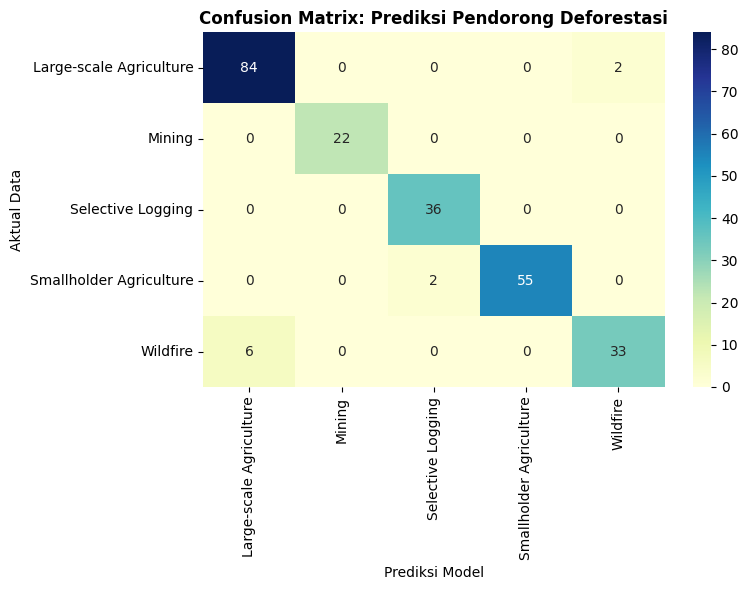

In [5]:
# SEL 5: EVALUASI MODEL & METRIK PERFORMA
def evaluate_driver_model(model, X_test, y_test, class_names):
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    macro_f1 = f1_score(y_test, y_pred, average='macro')

    print("="*50)
    print(" 📊 HASIL EVALUASI MODEL ATRIBUSI DEFORESTASI")
    print("="*50)
    print(f" • Overall Accuracy : {acc * 100:.2f}%")
    print(f" • Macro F1-Score   : {macro_f1:.4f}")
    print("="*50 + "\n")

    print("📋 Laporan Klasifikasi Rinci:")
    print(classification_report(y_test, y_pred, target_names=class_names))

    # Heatmap Confusion Matrix
    plt.figure(figsize=(8, 6))
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='YlGnBu',
                xticklabels=class_names, yticklabels=class_names)
    plt.title('Confusion Matrix: Prediksi Pendorong Deforestasi', fontsize=12, fontweight='bold')
    plt.xlabel('Prediksi Model')
    plt.ylabel('Aktual Data')
    plt.tight_layout()
    plt.show()

evaluate_driver_model(rf_model, X_test, y_test, label_encoder.classes_)

6. Fungsi Prediksi Pendorong Deforestasi Baru

In [6]:
# SEL 6: PREDIKSI ALERT DEFORESTASI BARU
def predict_new_deforestation_alert(model, scaler, label_encoder, alert_data):
    df_new = pd.DataFrame([alert_data])
    new_scaled = scaler.transform(df_new)

    pred_code = model.predict(new_scaled)[0]
    pred_driver = label_encoder.inverse_transform([pred_code])[0]

    probabilities = model.predict_proba(new_scaled)[0]
    confidence = np.max(probabilities) * 100

    return pred_driver, confidence

# --- UJI COBA TITIK ALERT BARU ---
new_satellite_alert = {
    'NDVI_Drop': 0.78,
    'Radar_Backscatter_dB': -17.5,
    'Area_Size_Ha': 12.4,
    'Bare_Soil_Index': 0.82,
    'Thermal_Anomaly': 0
}

predicted_driver, conf_score = predict_new_deforestation_alert(
    rf_model, scaler, label_encoder, new_satellite_alert
)

print("=== HASIL ATRIBUSI PENDORONG DEFORESTASI ===")
print("Data Sensor Alert Satelit:", new_satellite_alert)
print(f"Penyebab Utama Terdeteksi : *** {predicted_driver.upper()} ***")
print(f"Tingkat Kepercayaan Model : {conf_score:.2f}%")

=== HASIL ATRIBUSI PENDORONG DEFORESTASI ===
Data Sensor Alert Satelit: {'NDVI_Drop': 0.78, 'Radar_Backscatter_dB': -17.5, 'Area_Size_Ha': 12.4, 'Bare_Soil_Index': 0.82, 'Thermal_Anomaly': 0}
Penyebab Utama Terdeteksi : *** MINING ***
Tingkat Kepercayaan Model : 100.00%
